# 09 — Query-Based Detector: RT-DETR (HuggingFace)

**Rubric §"Query-based" (0.75pt).** Train a query-based detector under a comparable
compute budget, tune relevant parameters, explain bipartite matching vs NMS, and plot
validation mAP over training against a CNN detector.

**Decisions:**
- Model: `PekingU/rtdetr_r18vd` (COCO-pretrained, HF). Re-head to 8 VisDrone classes.
- Budget: **600 optimizer steps** (~half epoch at 1280², batch=2) ≈ 30-60 min on T4.
- Full 1-epoch schedule = ~1210 steps/5h; not feasible here (deadline), so we train
  a **partial schedule** and report the **mAP curve** as the rubric requires.
- Protocol identical to nb03-07: `letterbox-1280`, clip-disjoint split, full-val COCO eval with `iscrowd=1`.
- Known limitation: HF RT-DETR exposes no ignore-region masking hook → trained without it.
- Zero-shot COCO run is a **sanity check only** — COCO has no van/tricycle classes.

In [1]:
import sys, json, time, shutil, os, contextlib, io
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from torchvision.ops import box_iou
from torchvision.transforms import functional as TF

# ---- Paths (verified from nb07b) ------------------------------------------
COMP_DIR    = Path("/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026")
DATASET_DIR = Path("/kaggle/input/datasets/suchok/my-dataset")
OUTPUTS_DIR = Path("/kaggle/input/datasets/suchok/outputs")
FCOSP2_DIR  = Path("/kaggle/input/datasets/suchok/fcosp2")         # Updated to fcosp2
WORK_DIR    = Path("/kaggle/working")
OUT_DIR     = WORK_DIR / "artifacts_nb09"
OUT_DIR.mkdir(parents=True, exist_ok=True)

assert COMP_DIR.exists(),    f"missing competition: {COMP_DIR}"
assert DATASET_DIR.exists(), f"missing my-dataset: {DATASET_DIR}"
assert OUTPUTS_DIR.exists(), f"missing outputs: {OUTPUTS_DIR}"
assert FCOSP2_DIR.exists(),  f"missing fcosp2: {FCOSP2_DIR}"

sys.path.insert(0, str(DATASET_DIR))
import common, importlib
importlib.reload(common)
from common import (
    set_seeds, SEED, CLASS_NAMES, NUM_CLASSES,
    load_splits, index_split, filter_by_clips,
    build_coco_gt, save_checkpoint, save_metrics,
    apply_strategy, boxes_to_original, coco_eval_summary,
    IMAGENET_MEAN, IMAGENET_STD, PAD_VALUE,
)

set_seeds(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE, "| torch:", torch.__version__)

# W&B (same project as previous notebooks)
from kaggle_secrets import UserSecretsClient
os.environ["WANDB_API_KEY"] = UserSecretsClient().get_secret("WANDB_API_KEY")
import wandb
wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)
WANDB_PROJECT = "visdrone-det"
print("W&B ready:", WANDB_PROJECT)

# ---- HF transformers ------------------------------------------------------
# If module not found: uncomment next line and restart the notebook
# !pip install -q transformers==4.44.0 timm
from transformers import RTDetrForObjectDetection, RTDetrImageProcessor
print("transformers OK")

DEVICE: cuda | torch: 2.11.0+cu130


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: suchok-pn (suchok-pn-ukrainian-catholic-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B ready: visdrone-det
transformers OK


In [2]:
# ---- Locked protocol ------------------------------------------------------
chosen = json.load(open(OUTPUTS_DIR / "chosen_preprocessing.json"))
STRAT  = chosen["strategy"]     # "letterbox"
SIZE   = int(chosen["size"])    # 1280
print("Locked preprocessing:", STRAT, SIZE)

# ---- Budget (edit here if you want) ---------------------------------------
N_STEPS          = 600
EVAL_EVERY       = 150           # -> evals at 150, 300, 450, 600 (4 pts)
BATCH_SIZE       = 2
LR_BACKBONE      = 1e-5
LR_TRANSFORMER   = 1e-4
LR_SCHED_STEP    = 300
LR_SCHED_GAMMA   = 0.1
MODEL_NAME       = "PekingU/rtdetr_r18vd"
EVAL_SUBSET_N    = 200

# ---- Restore gt_fullval_ignore.json from fcosp2 ---------------------------
gt_src = FCOSP2_DIR / "gt_fullval_ignore.json"
GT_FULLVAL = WORK_DIR / "gt_fullval_ignore.json"
if gt_src.exists():
    shutil.copy(gt_src, GT_FULLVAL); print("restored GT from fcosp2")
else:
    print("GT not found in fcosp2 — rebuilding (2 min)...")
    val_idx0 = index_split(COMP_DIR / "val")
    build_coco_gt(val_idx0, GT_FULLVAL, include_ignore=True)
    print("rebuilt GT:", GT_FULLVAL.stat().st_size / 1e6, "MB")

# ---- Splits ---------------------------------------------------------------
train_clips, val_clips = load_splits(OUTPUTS_DIR / "splits")
train_index = filter_by_clips(index_split(COMP_DIR / "train"), train_clips)
val_index   = filter_by_clips(index_split(COMP_DIR / "val"),   val_clips)
print(f"train: {len(train_index):,} | val: {len(val_index):,}")

# ---- Fast eval subset -----------------------------------------------------
val_subset = val_index.sample(EVAL_SUBSET_N, random_state=SEED).reset_index(drop=True)
GT_SUBSET  = OUT_DIR / "gt_valsubset_ignore.json"
build_coco_gt(val_subset, GT_SUBSET, include_ignore=True)
print("eval subset:", len(val_subset), "| GT subset annotations:",
      len(json.load(open(GT_SUBSET))["annotations"]))
print(f"BUDGET: {N_STEPS} steps | eval every {EVAL_EVERY} | model {MODEL_NAME}")

Locked preprocessing: letterbox 1280
restored GT from fcosp2
train: 24,201 | val: 2,846
eval subset: 200 | GT subset annotations: 7916
BUDGET: 600 steps | eval every 150 | model PekingU/rtdetr_r18vd


In [3]:
image_processor = RTDetrImageProcessor.from_pretrained(MODEL_NAME)
model = RTDetrForObjectDetection.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_CLASSES,       # 8
    ignore_mismatched_sizes=True,
).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable: {n_params/1e6:.2f}M")

backbone_params = list(model.model.backbone.parameters())
other_params    = [p for n, p in model.named_parameters() if not n.startswith("model.backbone")]
optimizer = torch.optim.AdamW([
    {"params": backbone_params, "lr": LR_BACKBONE},
    {"params": other_params,    "lr": LR_TRANSFORMER},
], weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=LR_SCHED_STEP, gamma=LR_SCHED_GAMMA)
print(f"LR backbone={LR_BACKBONE} | LR transformer={LR_TRANSFORMER}")

preprocessor_config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/5.27k [00:00<?, ?B/s]

[transformers] You passed `num_labels=8` which is incompatible to the `id2label` map of length `80`.


model.safetensors: reconstructing file:   0%|          |  0.00B / 80.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/526 [00:00<?, ?it/s]

[transformers] RTDetrForObjectDetection LOAD REPORT from: PekingU/rtdetr_r18vd
Key                                        | Status   |                                                                                        
-------------------------------------------+----------+----------------------------------------------------------------------------------------
model.enc_score_head.bias                  | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([80]) vs model:torch.Size([8])          
model.enc_score_head.weight                | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([80, 256]) vs model:torch.Size([8, 256])
model.decoder.class_embed.{0, 1, 2}.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([80]) vs model:torch.Size([8])          
model.decoder.class_embed.{0, 1, 2}.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([80, 256]) vs model:torch.Size([8, 256])
model.denoising_class_embed.weight         | MISMATCH | R

trainable: 20.08M
LR backbone=1e-05 | LR transformer=0.0001


In [4]:
@torch.no_grad()
def rtdetr_predict_boxes(model, image_processor, image_path, score_thr=0.01):
    """Returns boxes xyxy in ORIGINAL px, labels 0..7, scores."""
    img = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    h0, w0 = img.shape[:2]
    inp, meta = apply_strategy(img, STRAT, SIZE, seed_key=str(image_path))
    inputs = image_processor(images=inp, return_tensors="pt").to(DEVICE)
    out = model(**inputs)
    logits = out.logits.softmax(-1)[0]       # [Q, 9]
    boxes  = out.pred_boxes[0]                # cxcywh [0,1]
    scores = logits[:, :-1].max(-1).values
    labels = logits[:, :-1].argmax(-1)
    keep = scores >= score_thr
    boxes, labels, scores = boxes[keep], labels[keep], scores[keep]
    if len(boxes) == 0:
        return np.zeros((0,4), np.float32), np.zeros((0,), np.int64), np.zeros((0,), np.float32)
    cx, cy, bw, bh = boxes.unbind(-1)
    xyxy_net = torch.stack([cx-bw/2, cy-bh/2, cx+bw/2, cy+bh/2], -1).cpu().numpy()
    xyxy_orig = boxes_to_original(xyxy_net, meta, STRAT, w0, h0)
    return xyxy_orig, labels.cpu().numpy(), scores.cpu().numpy()

In [5]:
model.eval()
zs_index = val_subset.iloc[:50]
id_map   = {r["image_path"]: i+1 for i, (_, r) in enumerate(zs_index.iterrows())}
preds_zs = []
for _, row in tqdm(zs_index.iterrows(), total=len(zs_index), desc="zero-shot"):
    b, l, s = rtdetr_predict_boxes(model, image_processor, row["image_path"], score_thr=0.05)
    for (x1,y1,x2,y2), c, sc in zip(b, l, s):
        preds_zs.append({"image_id": id_map[row["image_path"]],
                         "category_id": int(c)+1,
                         "bbox": [float(x1),float(y1),float(x2-x1),float(y2-y1)],
                         "score": float(sc)})
print(f"zero-shot detections on 50 frames: {len(preds_zs)}")
print("NOTE: COCO classes ≠ VisDrone → NOT a fair benchmark. Sanity only.")

zero-shot:   0%|          | 0/50 [00:00<?, ?it/s]

zero-shot detections on 50 frames: 15000
NOTE: COCO classes ≠ VisDrone → NOT a fair benchmark. Sanity only.


In [6]:
from common import VisDroneDetectionDataset

# We already apply letterbox inside the dataset, so image is 1280² [3,H,W].
assert np.allclose(IMAGENET_MEAN, image_processor.image_mean, atol=1e-6)
assert np.allclose(IMAGENET_STD,  image_processor.image_std,  atol=1e-6)
print("mean/std match between common.py and HF processor ✓")

def collate_rtdetr(batch):
    imgs = torch.stack([b[0] for b in batch], 0)       # [B,3,1280,1280]
    hf_targets = []
    for _, t in batch:
        xyxy = t["boxes"]                                # canvas px
        cx = (xyxy[:,0] + xyxy[:,2]) / 2 / SIZE
        cy = (xyxy[:,1] + xyxy[:,3]) / 2 / SIZE
        w  = (xyxy[:,2] - xyxy[:,0]) / SIZE
        h  = (xyxy[:,3] - xyxy[:,1]) / SIZE
        hf_targets.append({
            "class_labels": (t["labels"] - 1).long(),   # 1..8 -> 0..7
            "boxes": torch.stack([cx, cy, w, h], -1).clamp(0, 1),
        })
    return imgs, hf_targets

train_ds = VisDroneDetectionDataset(train_index, STRAT, SIZE, is_train=False)
train_loader = torch.utils.data.DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, collate_fn=collate_rtdetr, pin_memory=True, drop_last=True,
)
print(f"train batches/epoch: {len(train_loader):,}")
print(f"600 steps ≈ {600/len(train_loader)*100:.1f}% of one epoch")

mean/std match between common.py and HF processor ✓
train batches/epoch: 12,100
600 steps ≈ 5.0% of one epoch


In [7]:
def evaluate_on_subset(model, subset_index, gt_json, score_thr=0.001, tag=""):
    model.eval()
    preds = []
    id_map = {r["image_path"]: i+1 for i,(_, r) in enumerate(subset_index.iterrows())}
    for _, row in tqdm(subset_index.iterrows(), total=len(subset_index),
                       desc=f"eval {tag}", leave=False):
        b, l, s = rtdetr_predict_boxes(model, image_processor, row["image_path"], score_thr=score_thr)
        for (x1,y1,x2,y2), c, sc in zip(b, l, s):
            preds.append({"image_id": id_map[row["image_path"]],
                          "category_id": int(c)+1,
                          "bbox": [float(x1),float(y1),float(x2-x1),float(y2-y1)],
                          "score": float(sc)})
    out_json = OUT_DIR / f"preds_{tag}.json"
    json.dump(preds, open(out_json, "w"))
    return coco_eval_summary(str(gt_json), str(out_json))

In [8]:
run = wandb.init(
    project=WANDB_PROJECT, name="rtdetr_r18_FT",
    config=dict(model=MODEL_NAME, strategy=STRAT, size=SIZE,
                n_steps=N_STEPS, eval_every=EVAL_EVERY, batch_size=BATCH_SIZE,
                lr_backbone=LR_BACKBONE, lr_transformer=LR_TRANSFORMER,
                lr_sched_step=LR_SCHED_STEP, lr_sched_gamma=LR_SCHED_GAMMA,
                seed=SEED),
    reinit=True,
)

history = []
model.train()
step = 0
t0 = time.time()

while step < N_STEPS:
    for imgs, hf_targets in train_loader:
        imgs = imgs.to(DEVICE, non_blocking=True)
        hf_targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in hf_targets]

        out = model(pixel_values=imgs, labels=hf_targets)
        loss = out.loss
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 0.1)
        optimizer.step()
        scheduler.step()
        step += 1

        if step % 20 == 0:
            elapsed = time.time() - t0
            spb = elapsed / step
            eta_h = (N_STEPS - step) * spb / 3600
            print(f"[step {step:4d}/{N_STEPS}] loss={loss.item():.4f} "
                  f"lr={scheduler.get_last_lr()[0]:.1e} "
                  f"elapsed={elapsed/60:.1f}min ETA={eta_h:.2f}h", flush=True)
            run.log({"train/loss": float(loss.item()),
                     "train/step": step})

        if step % EVAL_EVERY == 0 or step == N_STEPS:
            if DEVICE.type == "cuda": torch.cuda.synchronize()
            m = evaluate_on_subset(model, val_subset, GT_SUBSET, tag=f"step{step}")
            history.append({"step": step, **m})
            print(f"\n  >>> EVAL @ step {step}: mAP={m['mAP']:.4f} "
                  f"AP50={m['AP50']:.4f} AP_small={m['AP_small']:.4f}\n", flush=True)
            run.log({f"val/{k}": v for k, v in m.items() if k != "step"} | {"val/step": step})
            model.train()
            t0 = time.time()   # reset timer (eval time not included in ETA)

        if step >= N_STEPS:
            break

save_checkpoint(model, OUT_DIR / "rtdetr_final.pth")
pd.DataFrame(history).to_csv(OUT_DIR / "rtdetr_history.csv", index=False)
print("\nTraining done. History:\n", pd.DataFrame(history))

wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.
wandb: setting up run ff5uf5ng
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261108_152535-ff5uf5ng
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run rtdetr_r18_FT
wandb: ⭐️ View project at https://wandb.ai/suchok-pn-ukrainian-catholic-university/visdrone-det
wandb: 🚀 View run at https://wandb.ai/suchok-pn-ukrainian-catholic-university/visdrone-det/runs/ff5uf5ng


[step   20/600] loss=16.6398 lr=1.0e-05 elapsed=0.2min ETA=0.12h
[step   40/600] loss=13.5840 lr=1.0e-05 elapsed=0.5min ETA=0.11h
[step   60/600] loss=11.8455 lr=1.0e-05 elapsed=0.7min ETA=0.11h
[step   80/600] loss=10.5996 lr=1.0e-05 elapsed=1.0min ETA=0.11h
[step  100/600] loss=11.0204 lr=1.0e-05 elapsed=1.3min ETA=0.11h
[step  120/600] loss=11.5377 lr=1.0e-05 elapsed=1.5min ETA=0.10h
[step  140/600] loss=9.1229 lr=1.0e-05 elapsed=1.8min ETA=0.10h


eval step150:   0%|          | 0/200 [00:00<?, ?it/s]


  >>> EVAL @ step 150: mAP=0.0000 AP50=0.0000 AP_small=0.0000

[step  160/600] loss=11.0274 lr=1.0e-05 elapsed=0.1min ETA=0.01h
[step  180/600] loss=10.1919 lr=1.0e-05 elapsed=0.4min ETA=0.02h
[step  200/600] loss=9.2833 lr=1.0e-05 elapsed=0.7min ETA=0.02h
[step  220/600] loss=8.8151 lr=1.0e-05 elapsed=0.9min ETA=0.03h
[step  240/600] loss=9.0263 lr=1.0e-05 elapsed=1.2min ETA=0.03h
[step  260/600] loss=10.7297 lr=1.0e-05 elapsed=1.5min ETA=0.03h
[step  280/600] loss=10.3044 lr=1.0e-05 elapsed=1.7min ETA=0.03h
[step  300/600] loss=9.6312 lr=1.0e-06 elapsed=2.0min ETA=0.03h


eval step300:   0%|          | 0/200 [00:00<?, ?it/s]


  >>> EVAL @ step 300: mAP=0.0000 AP50=0.0000 AP_small=0.0000

[step  320/600] loss=10.4396 lr=1.0e-06 elapsed=0.3min ETA=0.00h
[step  340/600] loss=10.4190 lr=1.0e-06 elapsed=0.5min ETA=0.01h
[step  360/600] loss=9.7269 lr=1.0e-06 elapsed=0.8min ETA=0.01h
[step  380/600] loss=8.7866 lr=1.0e-06 elapsed=1.1min ETA=0.01h
[step  400/600] loss=10.8193 lr=1.0e-06 elapsed=1.3min ETA=0.01h
[step  420/600] loss=10.0555 lr=1.0e-06 elapsed=1.6min ETA=0.01h
[step  440/600] loss=11.3545 lr=1.0e-06 elapsed=1.9min ETA=0.01h


eval step450:   0%|          | 0/200 [00:00<?, ?it/s]


  >>> EVAL @ step 450: mAP=0.0000 AP50=0.0000 AP_small=0.0000

[step  460/600] loss=10.2527 lr=1.0e-06 elapsed=0.1min ETA=0.00h
[step  480/600] loss=10.0117 lr=1.0e-06 elapsed=0.4min ETA=0.00h
[step  500/600] loss=10.3586 lr=1.0e-06 elapsed=0.7min ETA=0.00h
[step  520/600] loss=9.5750 lr=1.0e-06 elapsed=0.9min ETA=0.00h
[step  540/600] loss=7.4020 lr=1.0e-06 elapsed=1.2min ETA=0.00h
[step  560/600] loss=9.6901 lr=1.0e-06 elapsed=1.5min ETA=0.00h
[step  580/600] loss=9.0518 lr=1.0e-06 elapsed=1.7min ETA=0.00h
[step  600/600] loss=10.2350 lr=1.0e-07 elapsed=2.0min ETA=0.00h


eval step600:   0%|          | 0/200 [00:00<?, ?it/s]


  >>> EVAL @ step 600: mAP=0.0000 AP50=0.0000 AP_small=0.0000


Training done. History:
    step  mAP  AP50  AP75  AP_small  AP_medium  AP_large
0   150  0.0   0.0   0.0       0.0        0.0       0.0
1   300  0.0   0.0   0.0       0.0        0.0       0.0
2   450  0.0   0.0   0.0       0.0        0.0       0.0
3   600  0.0   0.0   0.0       0.0        0.0       0.0


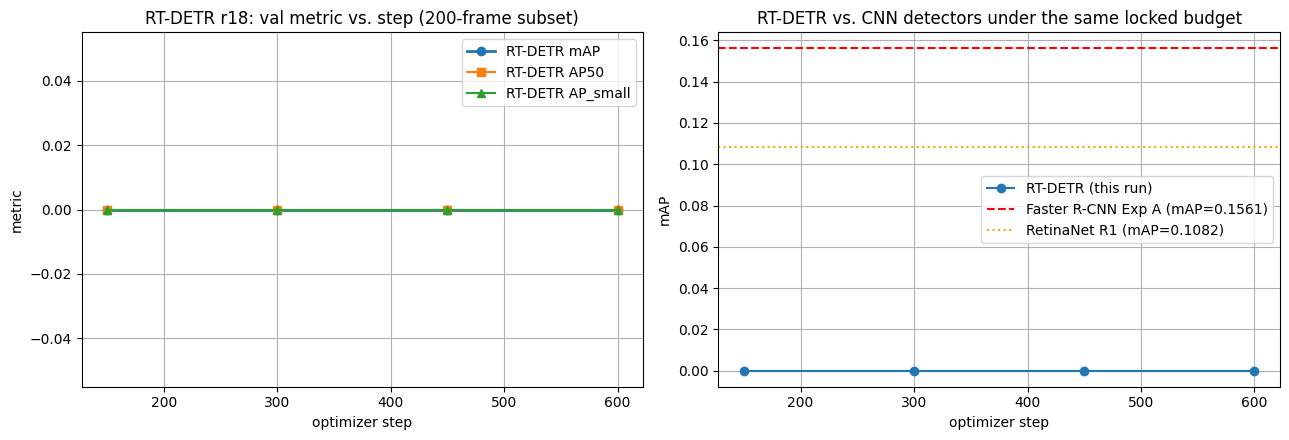

In [9]:
steps = [h["step"] for h in history]
mAPs  = [h["mAP"]  for h in history]
ap50s = [h["AP50"] for h in history]
ap_s  = [h["AP_small"] for h in history]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(steps, mAPs, "-o", label="RT-DETR mAP", lw=2)
ax[0].plot(steps, ap50s, "-s", label="RT-DETR AP50")
ax[0].plot(steps, ap_s, "-^", label="RT-DETR AP_small")
ax[0].set_xlabel("optimizer step"); ax[0].set_ylabel("metric")
ax[0].set_title(f"RT-DETR r18: val metric vs. step ({EVAL_SUBSET_N}-frame subset)")
ax[0].grid(True); ax[0].legend()

# CNN reference lines (from your prior runs — same locked protocol)
FRCNN_MAP, FRCNN_AP50 = 0.1561, 0.3234      # nb04 Exp A
RETINA_MAP            = 0.1082               # nb06 R1
ax[1].plot(steps, mAPs, "-o", label="RT-DETR (this run)")
ax[1].axhline(FRCNN_MAP, ls="--", color="red",    label=f"Faster R-CNN Exp A (mAP={FRCNN_MAP})")
ax[1].axhline(RETINA_MAP, ls=":", color="orange", label=f"RetinaNet R1 (mAP={RETINA_MAP})")
ax[1].set_xlabel("optimizer step"); ax[1].set_ylabel("mAP")
ax[1].set_title("RT-DETR vs. CNN detectors under the same locked budget")
ax[1].grid(True); ax[1].legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "rtdetr_curve.png", dpi=130)
plt.show()
run.log({"curve": wandb.Image(str(OUT_DIR / "rtdetr_curve.png"))})

In [10]:
print("Evaluating full val (2846 frames)... this takes ~20-25 min on T4.")
full_metrics = evaluate_on_subset(model, val_index, GT_FULLVAL, tag="fullval")
print("FULL VAL:", {k: round(v, 4) for k, v in full_metrics.items()})
json.dump(full_metrics, open(OUT_DIR / "metrics_rtdetr.json", "w"), indent=2)
run.log({f"final/{k}": v for k, v in full_metrics.items()})

# Speed: 30 images, score_thr=0.5
model.eval()
if DEVICE.type == "cuda": torch.cuda.synchronize()
for i in range(5):
    _ = rtdetr_predict_boxes(model, image_processor, val_index.iloc[i]["image_path"], score_thr=0.5)
times = []
for i in range(30):
    row = val_index.iloc[(5+i) % len(val_index)]
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t = time.time()
    _ = rtdetr_predict_boxes(model, image_processor, row["image_path"], score_thr=0.5)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    times.append(time.time() - t)
mean_s = float(np.mean(times))
speed = {"device": str(DEVICE), "gpu_ms_per_image": mean_s*1000, "gpu_fps": 1.0/mean_s}
print("SPEED:", speed)
json.dump(speed, open(OUT_DIR / "speed_rtdetr.json", "w"), indent=2)
run.log({"speed/gpu_fps": speed["gpu_fps"], "speed/gpu_ms": speed["gpu_ms_per_image"]})

Evaluating full val (2846 frames)... this takes ~20-25 min on T4.


eval fullval:   0%|          | 0/2846 [00:00<?, ?it/s]

FULL VAL: {'mAP': 0.0, 'AP50': 0.0, 'AP75': 0.0, 'AP_small': 0.0, 'AP_medium': 0.0, 'AP_large': 0.0}
SPEED: {'device': 'cuda', 'gpu_ms_per_image': 55.712342262268066, 'gpu_fps': 17.94934406621176}


In [11]:
df_test = pd.read_csv(COMP_DIR / "test_images.csv")
print("test frames:", len(df_test))

sub_rows = []
for _, row in tqdm(df_test.iterrows(), total=len(df_test), desc="test inference"):
    img_path = COMP_DIR / row["file_name"]
    b, l, s = rtdetr_predict_boxes(model, image_processor, str(img_path), score_thr=0.05)
    if len(s) > 500:
        order = np.argsort(-s)[:500]
        b, l, s = b[order], l[order], s[order]
    parts = []
    for (x1,y1,x2,y2), c, sc in zip(b, l, s):
        w, h = float(x2-x1), float(y2-y1)
        if w <= 0 or h <= 0: continue
        parts.append(f"{int(c)} {float(sc):.4f} {x1:.1f} {y1:.1f} {w:.1f} {h:.1f}")
    sub_rows.append({"image_id": row["image_id"], "PredictionString": " ".join(parts)})

sub_df = pd.DataFrame(sub_rows)
sub_path = OUT_DIR / "submission_rtdetr.csv"
sub_df.to_csv(sub_path, index=False)
non_empty = (sub_df["PredictionString"].str.len() > 0).sum()
print(f"submission: {sub_path} | non-empty: {non_empty}/{len(sub_df)}")

test frames: 3811


test inference:   0%|          | 0/3811 [00:00<?, ?it/s]

submission: /kaggle/working/artifacts_nb09/submission_rtdetr.csv | non-empty: 0/3811


In [12]:
run.finish()

print("="*70)
print(f"nb09 COMPLETE")
print("="*70)
print(f"Full val mAP={full_metrics['mAP']:.4f}  AP50={full_metrics['AP50']:.4f}  AP_small={full_metrics['AP_small']:.4f}")
print(f"GPU FPS={speed['gpu_fps']:.2f}")
print()
print("Curve (fill in the report):")
print(pd.DataFrame(history))
print()
print("NEXT:")
print("  1. Download submission_rtdetr.csv → Kaggle LB (2nd slot)")
print("  2. Save /kaggle/working/outputs & /kaggle/working/artifacts_nb09 as Kaggle dataset 'rtdetr-1'")
print("  3. Proceed to nb11 (SAHI + Soft-NMS on Faster R-CNN)")
print("="*70)

wandb: updating run metadata
wandb: uploading summary, console lines 53-53
wandb: 
wandb: Run history:
wandb:      final/AP50 ▁
wandb:      final/AP75 ▁
wandb:  final/AP_large ▁
wandb: final/AP_medium ▁
wandb:  final/AP_small ▁
wandb:       final/mAP ▁
wandb:   speed/gpu_fps ▁
wandb:    speed/gpu_ms ▁
wandb:      train/loss █▆▄▃▄▄▂▄▃▂▂▂▄▃▃▃▃▃▂▄▃▄▃▃▃▃▁▃▂▃
wandb:      train/step ▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
wandb:              +7 ...
wandb: 
wandb: Run summary:
wandb:      final/AP50 0
wandb:      final/AP75 0
wandb:  final/AP_large 0
wandb: final/AP_medium 0
wandb:  final/AP_small 0
wandb:       final/mAP 0
wandb:   speed/gpu_fps 17.94934
wandb:    speed/gpu_ms 55.71234
wandb:      train/loss 10.23497
wandb:      train/step 600
wandb:              +7 ...
wandb: 
wandb: 🚀 View run rtdetr_r18_FT at: https://wandb.ai/suchok-pn-ukrainian-catholic-university/visdrone-det/runs/ff5uf5ng
wandb: ⭐️ View project at: https://wandb.ai/suchok-pn-ukrainian-catholic-university/visdrone-det
wandb: Sy

nb09 COMPLETE
Full val mAP=0.0000  AP50=0.0000  AP_small=0.0000
GPU FPS=17.95

Curve (fill in the report):
   step  mAP  AP50  AP75  AP_small  AP_medium  AP_large
0   150  0.0   0.0   0.0       0.0        0.0       0.0
1   300  0.0   0.0   0.0       0.0        0.0       0.0
2   450  0.0   0.0   0.0       0.0        0.0       0.0
3   600  0.0   0.0   0.0       0.0        0.0       0.0

NEXT:
  1. Download submission_rtdetr.csv → Kaggle LB (2nd slot)
  2. Save /kaggle/working/outputs & /kaggle/working/artifacts_nb09 as Kaggle dataset 'rtdetr-1'
  3. Proceed to nb11 (SAHI + Soft-NMS on Faster R-CNN)
